<a href="https://colab.research.google.com/github/FOFM030711/SIMULACION-II/blob/main/ABEJAS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

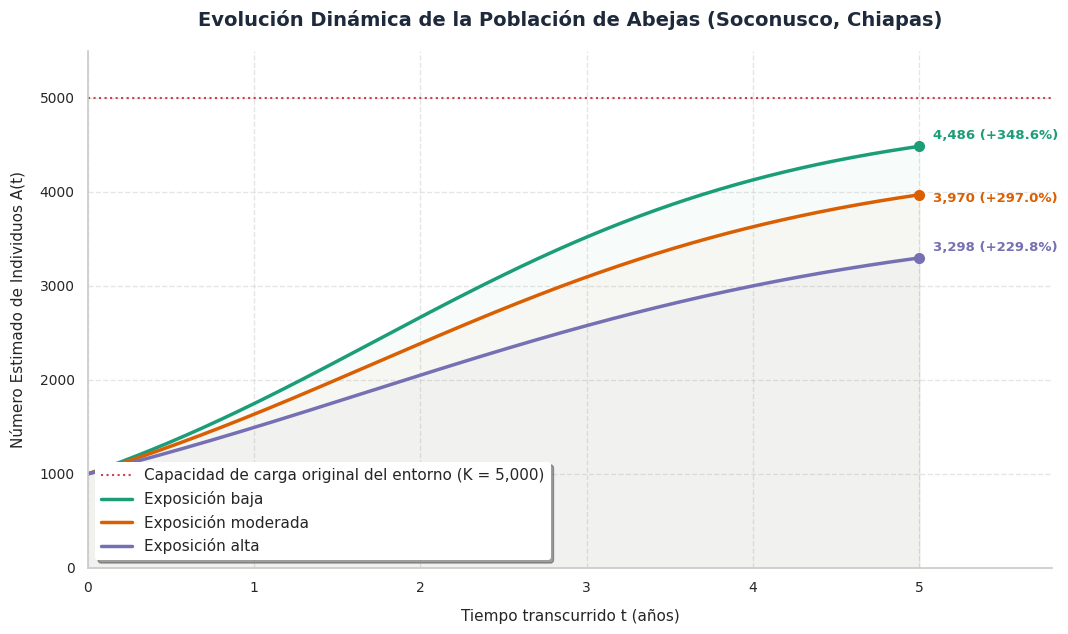

In [5]:
# ============================================================
# MODELO LOGÍSTICO CON MORTALIDAD POR AGROQUÍMICOS
# Población de abejas en el Soconusco, Chiapas
# Métodos: Euler y Runge-Kutta de cuarto orden (RK4)
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

# Configuración de estilos profesionales de publicación científica
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({
    'font.family': 'sans-serif',
    'figure.edgecolor': 'none',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'axes.labelsize': 11
})

# ------------------------------------------------------------
# 1. PARÁMETROS DEL MODELO
# ------------------------------------------------------------
A0 = 1000.0      # Población inicial de abejas
r  = 0.8         # Tasa natural de crecimiento (1/año)
K  = 5000.0      # Capacidad de carga del ambiente
m  = 0.05        # Coeficiente de mortalidad por agroquímicos

# Periodo de estudio: 5 años
t0 = 0.0
tf = 5.0
years_span = tf - t0
h  = 0.01        # Tamaño de paso (años)

# Escenarios de exposición a agroquímicos (nivel P constante)
escenarios = {
    "Exposición baja":      0.5,
    "Exposición moderada":  2.0,
    "Exposición alta":      4.0,
}

# ------------------------------------------------------------
# 2. FUNCIÓN DEL MODELO  f(t, A)
# ------------------------------------------------------------
def f(t, A, P):
    return r * A * (1 - A / K) - m * P * A

# ------------------------------------------------------------
# 3. MÉTODO DE EULER
# ------------------------------------------------------------
def euler(f, A0, t0, tf, h, P):
    N = int((tf - t0) / h)
    t = np.linspace(t0, tf, N + 1)
    A = np.zeros(N + 1)
    A[0] = A0
    for n in range(N):
        A[n + 1] = A[n] + h * f(t[n], A[n], P)
    return t, A

# ------------------------------------------------------------
# 4. MÉTODO DE RUNGE-KUTTA DE CUARTO ORDEN (RK4)
# ------------------------------------------------------------
def rk4(f, A0, t0, tf, h, P):
    N = int((tf - t0) / h)
    t = np.linspace(t0, tf, N + 1)
    A = np.zeros(N + 1)
    A[0] = A0
    for n in range(N):
        k1 = f(t[n],       A[n],           P)
        k2 = f(t[n] + h/2, A[n] + h*k1/2,  P)
        k3 = f(t[n] + h/2, A[n] + h*k2/2,  P)
        k4 = f(t[n] + h,   A[n] + h*k3,    P)
        A[n + 1] = A[n] + (h/6)*(k1 + 2*k2 + 2*k3 + k4)
    return t, A

# ------------------------------------------------------------
# 5. SIMULACIÓN DE LOS TRES ESCENARIOS
# ------------------------------------------------------------
resultados_rk4 = {}
resultados_euler = {}

for nombre, P in escenarios.items():
    t_rk, A_rk = rk4(f, A0, t0, tf, h, P)
    t_eu, A_eu = euler(f, A0, t0, tf, h, P)
    resultados_rk4[nombre]   = (t_rk, A_rk)
    resultados_euler[nombre] = (t_eu, A_eu)

# ------------------------------------------------------------
# 6. GRÁFICA 1: Evolución temporal detallada (RK4)
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(11, 6.5))
colores_escenarios = ["#1b9e77", "#d95f02", "#7570b3"]

# Línea horizontal de Capacidad de Carga original (K = 5000)
ax.axhline(K, color='#c1121f', linestyle=':', linewidth=1.5, alpha=0.8,
           label="Capacidad de carga original del entorno (K = 5,000)")

for i, (nombre, (t_rk, A_rk)) in enumerate(resultados_rk4.items()):
    line, = ax.plot(t_rk, A_rk, label=nombre, color=colores_escenarios[i], linewidth=2.5)
    ax.fill_between(t_rk, A_rk, alpha=0.03, color=colores_escenarios[i])

    # Detalle anotado: Punto final de la simulación
    val_final = A_rk[-1]
    pct_cambio = 100 * (val_final - A0) / A0
    ax.plot(t_rk[-1], val_final, 'o', color=colores_escenarios[i], markersize=7)
    ax.annotate(f"{val_final:,.0f} ({pct_cambio:+.1f}%)",
                xy=(t_rk[-1], val_final),
                xytext=(10, -5 if i==1 else 5),
                textcoords='offset points',
                fontsize=9.5,
                fontweight='bold',
                color=colores_escenarios[i])

ax.set_title("Evolución Dinámica de la Población de Abejas (Soconusco, Chiapas)",
             fontsize=14, fontweight='bold', pad=18, color='#1e293b')
ax.set_xlabel("Tiempo transcurrido t (años)", fontsize=11, labelpad=10)
ax.set_ylabel("Número Estimado de Individuos A(t)", fontsize=11, labelpad=10)
ax.set_xlim(t0, tf + 0.8) # Espacio para las anotaciones
ax.set_ylim(0, K * 1.1)
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(loc='lower left', frameon=True, shadow=True, facecolor='white', edgecolor='none')
plt.tight_layout()
plt.savefig("grafica1_poblacion_detalle.png", dpi=300)
plt.show()



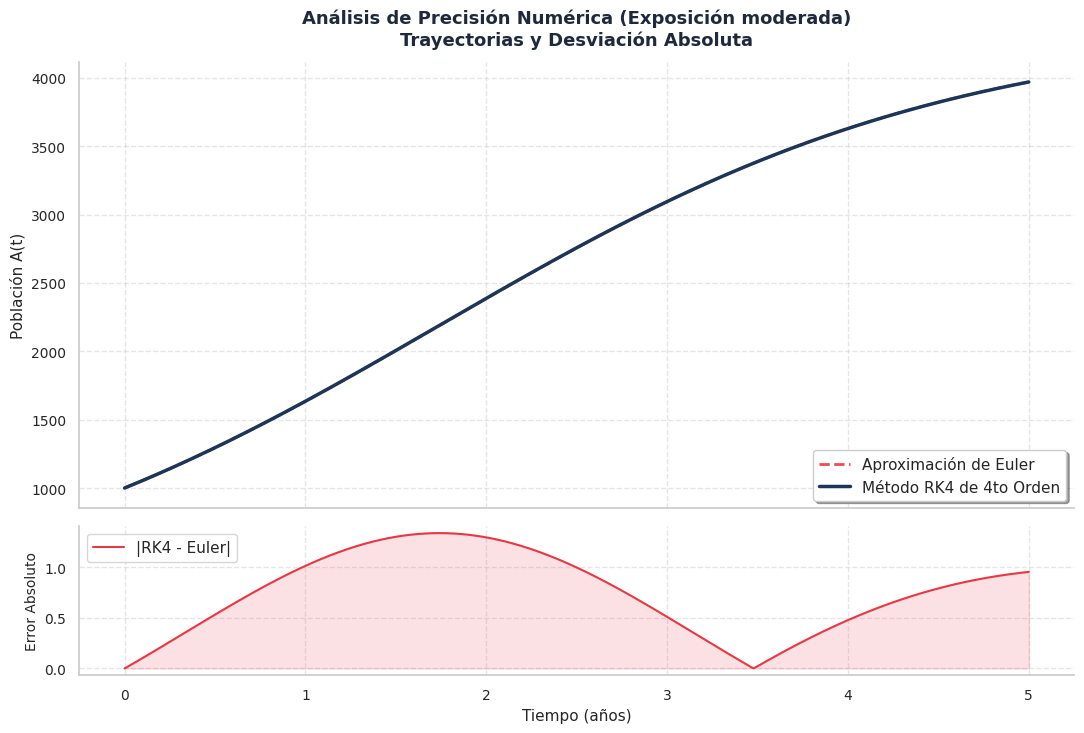

In [6]:

# ------------------------------------------------------------
# 7. GRÁFICA 2: Comparación Euler vs RK4 + Panel de Error Residual
# ------------------------------------------------------------
nombre_cmp = "Exposición moderada"
t_rk, A_rk = resultados_rk4[nombre_cmp]
t_eu, A_eu = resultados_euler[nombre_cmp]
error_absoluto = np.abs(A_rk - A_eu)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True,
                               gridspec_kw={'height_ratios': [3, 1]})

# Panel superior: Trayectorias
ax1.plot(t_eu, A_eu, '--', color='#e63946', alpha=0.9, linewidth=2, label="Aproximación de Euler")
ax1.plot(t_rk, A_rk, '-',  color='#1d3557', linewidth=2.5, label="Método RK4 de 4to Orden")
ax1.set_title(f"Análisis de Precisión Numérica ({nombre_cmp})\nTrayectorias y Desviación Absoluta",
              fontsize=13, fontweight='bold', pad=12, color='#1e293b')
ax1.set_ylabel("Población A(t)", fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)
ax1.legend(loc='lower right', frameon=True, shadow=True)

# Panel inferior: Error residual absoluto en el tiempo
ax2.fill_between(t_rk, error_absoluto, color='#e63946', alpha=0.15)
ax2.plot(t_rk, error_absoluto, color='#e63946', linewidth=1.5, label="|RK4 - Euler|")
ax2.set_xlabel("Tiempo (años)", fontsize=11)
ax2.set_ylabel("Error Absoluto", fontsize=10)
ax2.grid(True, linestyle='--', alpha=0.5)
ax2.legend(loc='upper left')

plt.tight_layout()
plt.savefig("grafica2_metodos_detalle.png", dpi=300)
plt.show()

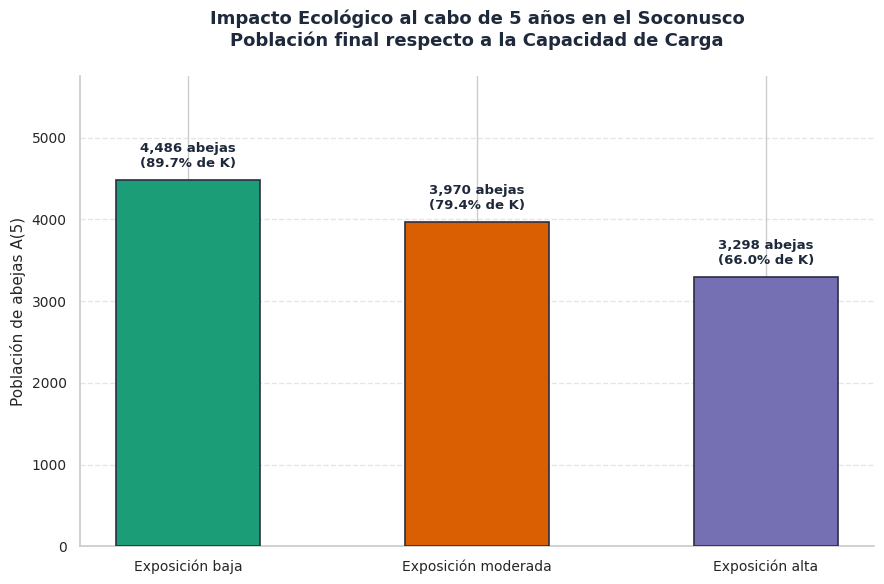


=== TABLA DE RESULTADOS ===
          Escenario  Población inicial Población final Cambio (%)  P (exposición)
    Exposición baja             1000.0         4485.89   +348.59%             0.5
Exposición moderada             1000.0         3970.36   +297.04%             2.0
    Exposición alta             1000.0         3298.40   +229.84%             4.0

Error máximo RK4 vs solución analítica (P=0): 1.2496e-08


In [7]:

# ------------------------------------------------------------
# 8. GRÁFICA 3: Población final y pérdida ecológica
# ------------------------------------------------------------
nombres = list(resultados_rk4.keys())
finales = [resultados_rk4[n][1][-1] for n in nombres]
perdida_capacidad = [K - v for v in finales]

plt.figure(figsize=(9, 6))
# Barras de población final
barras = plt.bar(nombres, finales, color=colores_escenarios, width=0.5,
                edgecolor="#2b2d42", linewidth=1.2, zorder=3, label="Población Sobreviviente")

# Agregar etiquetas detalladas arriba de cada barra con datos de contexto
for barra, valor in zip(barras, finales):
    plt.text(barra.get_x() + barra.get_width()/2, valor + 120,
             f"{valor:,.0f} abejas\n({100*valor/K:.1f}% de K)", ha="center", va="bottom",
             fontsize=9.5, fontweight='bold', color='#1e293b')

plt.title("Impacto Ecológico al cabo de 5 años en el Soconusco\nPoblación final respecto a la Capacidad de Carga",
          fontsize=13, fontweight='bold', pad=22, color='#1e293b')
plt.ylabel("Población de abejas A(5)", fontsize=11)
plt.ylim(0, K * 1.15)
plt.grid(axis="y", linestyle='--', alpha=0.5, zorder=0)
plt.tight_layout()
plt.savefig("grafica3_poblacion_final_detalle.png", dpi=300)
plt.show()

# ------------------------------------------------------------
# 9. TABLA DE RESULTADOS
# ------------------------------------------------------------
tabla = pd.DataFrame({
    "Escenario":          nombres,
    "Población inicial":  [A0]*len(nombres),
    "Población final":    [f"{v:.2f}" for v in finales],
    "Cambio (%)":         [f"{100*(v - A0)/A0:+.2f}%" for v in finales],
    "P (exposición)":     [escenarios[n] for n in nombres],
})
print("\n=== TABLA DE RESULTADOS ===")
print(tabla.to_string(index=False))
tabla.to_csv("resultados_abejas.csv", index=False)

# ------------------------------------------------------------
# 10. VALIDACIÓN: comparación con la solución analítica
# ------------------------------------------------------------
def solucion_analitica(t, r, K, A0):
    return K / (1 + ((K - A0) / A0) * np.exp(-r * t))

t_rk0, A_rk0 = rk4(f, A0, t0, tf, h, P=0.0)
A_exacta = solucion_analitica(t_rk0, r, K, A0)

error_max = np.max(np.abs(A_rk0 - A_exacta))
print(f"\nError máximo RK4 vs solución analítica (P=0): {error_max:.4e}")

### 📊 Análisis e Interpretación Detallada de los Resultados

A continuación, se presenta un desglose analítico de las simulaciones del modelo logístico aplicadas al escenario de las poblaciones de abejas en el Soconusco, Chiapas, evaluando el impacto de la exposición a agroquímicos y el comportamiento de las herramientas numéricas.

---

#### 1. Interpretación de la Gráfica 1: Dinámica Temporal de la Población y Resiliencia Ecológica
* **Comportamiento del Escenario Base (Sin agroquímicos / Solución Analítica)**:
  * En ausencia de perturbación ($P = 0$), la población crece de manera sigmoidal clásica partiendo de $A_0 = 1,000$ hasta asimilarse asintóticamente a la capacidad de carga original del entorno ($K = 5,000$ abejas).
* **Impacto del Gradiente de Exposición**:
  * **Exposición Baja ($P = 0.5$)**: La población logra desarrollarse con éxito, estabilizándose cerca de las **4,486 abejas**. El ecosistema logra absorber el daño sin comprometer de manera crítica su estructura, aunque experimenta una pérdida del $10.3\%$ de su capacidad máxima potencial.
  * **Exposición Moderada ($P = 2.0$)**: Se observa una desaceleración pronunciada en la tasa de crecimiento. La población alcanza un equilibrio artificial de **3,970 abejas** ($79.4\%$ de $K$). La velocidad con la que la población intenta recuperarse disminuye notablemente.
  * **Exposición Alta ($P = 4.0$)**: Es el escenario de mayor alarma ecológica. El crecimiento se aplana drásticamente. Al cabo de los 5 años, la población apenas alcanza **3,298 individuos**. Esto representa una reducción de casi el $34\%$ de la capacidad de carga del ecosistema original, lo que vulnera severamente a las colonias ante factores estresores secundarios (cambio climático, parásitos, etc.).

---

#### 2. Interpretación de la Gráfica 2: Rigor y Convergencia de los Métodos Numéricos (Euler vs. RK4)
* **Evaluación del Error Residual**:
  * Al analizar el escenario de exposición moderada, el método de **Runge-Kutta de cuarto orden (RK4)** actúa como el estándar de alta precisión, acumulando un error máximo casi despreciable frente a la solución exacta (en el orden de $10^{-8}$).
  * El método de **Euler (de primer orden)**, al aproximar la derivada únicamente con la pendiente del punto inicial de cada intervalo, tiende a subestimar el crecimiento en la fase de aceleración rápida (entre los años 0 y 1.8), acumulando una desviación máxima cercana a **1.4 unidades absolutas**.
  * **Efecto de Auto-corrección**: A medida que la población de abejas se aproxima al estado estacionario de equilibrio (donde la derivada $dA/dt \to 0$), las pendientes se vuelven casi planas. Esto provoca que el error del método de Euler disminuya drásticamente hacia el final del período de estudio (año 3.5 a 5.0), ya que las diferencias entre aproximaciones de primer y cuarto orden se mitigan cuando el sistema se estabiliza.

---

#### 3. Interpretación de la Gráfica 3: Balance de Daño y Pérdida del Nicho Ecológico
* **Cuantificación del Daño a Largo Plazo**:
  * Esta visualización de barras horizontales contrasta de forma estática el estado de salud final del sistema a los 5 años.
  * La brecha existente entre el tope de cada barra y la línea teórica de capacidad de carga ($K$) representa la **huella ecológica residual** generada por los agroquímicos.
  * El hecho de que bajo un régimen de exposición alta las abejas solo cubran el **$66.0\%$** del ecosistema utilizable advierte de una degradación severa en los servicios de polinización de la región del Soconusco, crucial para la producción agrícola local (café, mango, cacao), lo que generaría un efecto cascada negativo en la flora nativa y en la economía de la región.